# P2 Notebook 2 — Cleaning, Preprocessing & Image EDA

**Classes:** `cheetah`, `jaguar`, `leopard`, `ocelot`, `serval`

Notebook 1 left a folder of search results: 400 images per class, each recorded in
`data/P2_manifest.csv`. This notebook turns that folder into a clean, model-ready dataset. It
summarises the cleaning, documents what the images look like, chooses how to make them all one size,
and splits them 80/20 for Notebook 3.

Nothing is carried over from Notebook 1. The notebook reads the manifest and the image folders from
disk at the top.

## This notebook covers

1. Setup: loading the manifest and the image folders
2. Cleaning: the hand-cleaning summary, duplicate removal, and the final counts
3. Image EDA: sample grid, image dimensions, per-class mean image, grayscale share, class support
4. Preprocessing decisions: colour mode and resize strategy
5. Split and export: train/test arrays, the label→index mapping, and the manifest update

**Input:** `data/P2_manifest.csv` and the class folders in the local data folder (outside the repo).

**Output:** train and test arrays plus `label_map.json` in the local data folder, and three new
manifest columns: `kept`, `removal_reason` and `split`.

## 1. Setup

Three locations are used. `PROJECT_DIR` holds this notebook and `data/P2_manifest.csv`.
`IMAGE_DIR` is where Notebook 1 saved the images, with rejected images under `_rejected/`.
`PREP_DIR` is where this notebook writes the train and test arrays. Both image folders are outside the
project folder, so no image or array can be committed to the repo.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
plt.style.use('dark_background')

PROJECT_DIR = Path.home() / 'P2_Images'                      # notebook + data/P2_manifest.csv
IMAGE_DIR = Path.home() / 'MSDS565_data' / 'P2_images'       # Notebook 1's class folders
REJECT_DIR = IMAGE_DIR / '_rejected'                         # _rejected/<class>/<reason>/
PREP_DIR = Path.home() / 'MSDS565_data' / 'P2_prepared'      # this notebook's arrays
MANIFEST_PATH = PROJECT_DIR / 'data' / 'P2_manifest.csv'

HAND_REASONS = ['not_animal', 'drawing', 'wrong_species', 'unusable']
SEED = 42

In [2]:
manifest = pd.read_csv(MANIFEST_PATH, keep_default_na=False)
manifest['readable'] = manifest['readable'].astype(str).str.lower().eq('true')

# The columns this notebook adds. Dropped here if present, so a re-run rebuilds them
# rather than duplicating them; Notebook 1's columns are never touched.
NB2_COLUMNS = ['kept', 'removal_reason', 'split']
manifest = manifest.drop(columns=[c for c in NB2_COLUMNS if c in manifest.columns])

CLASSES = sorted(manifest['label'].unique())
print(f'{len(manifest)} manifest rows, {len(CLASSES)} classes: {CLASSES}')
print(f'columns: {list(manifest.columns)}')

2000 manifest rows, 5 classes: ['cheetah', 'jaguar', 'leopard', 'ocelot', 'serval']
columns: ['filename', 'label', 'query', 'image_url', 'source_url', 'title', 'width', 'height', 'readable']


Every image's hand-cleaning status is read from **where its file is now**. A file still in its class
folder passed hand cleaning. A file under `_rejected/<class>/<reason>/` was removed for that reason. A file
Notebook 1 marked unreadable was deleted there and is counted as `unreadable`. Nothing is tracked in a
separate list that could drift out of step with the folders. (Duplicates, in 2.2, are the one exception:
the notebook finds them itself and marks them in the manifest without moving any file.) Any manifest row whose file is in none of these
places is reported as `missing`, and the assertion stops the notebook, because a count that cannot
be accounted for is exactly what the prompt warns about.

In [3]:
def removal_reason(label, filename, readable):
    # '' = still in the class folder; otherwise the reason folder it was moved to.
    if (IMAGE_DIR / label / filename).exists():
        return ''
    for reason in HAND_REASONS:
        if (REJECT_DIR / label / reason / filename).exists():
            return reason
    return 'unreadable' if not readable else 'missing'


def refresh_status(df):
    reasons = [removal_reason(l, f, r) for l, f, r in zip(df['label'], df['filename'], df['readable'])]
    return df.assign(removal_reason=reasons)


manifest = refresh_status(manifest)
missing = manifest[manifest['removal_reason'] == 'missing']
assert missing.empty, f'{len(missing)} manifest rows have no file anywhere:\n{missing.head()}'

# Files on disk that the manifest does not know about would also break the accounting.
on_disk = {(p.parent.name, p.name) for c in CLASSES for p in (IMAGE_DIR / c).glob('*.jpg')}
in_manifest = set(zip(manifest['label'], manifest['filename']))
assert on_disk <= in_manifest, f'{len(on_disk - in_manifest)} files in class folders are not in the manifest'
print('Every manifest row is accounted for, and every file on disk is in the manifest.')

Every manifest row is accounted for, and every file on disk is in the manifest.


## 2. Cleaning

### 2.1 Hand cleaning

Every class folder was reviewed by hand, image by image. There is no reliable automated way to tell that a
search for "jaguar" returned a car advert, or that a "serval" result is a Savannah cat. Rejected
images were **moved, not deleted**, into one of four reason folders, so every removal is counted by
class and by reason directly from disk:

| Reason | What it covers |
|---|---|
| `not_animal` | Cars (Jaguar), logos and sports teams, leopard- and cheetah-print fabric and products, text graphics |
| `drawing` | Cartoons, illustrations, video-game and anime characters (Minecraft ocelot, *Kemono Friends* serval) |
| `wrong_species` | A real animal that is not the class: snow and clouded leopards, Savannah cats, other cats, non-cats, or two species with neither clearly the subject |
| `unusable` | Collages, black (melanistic) leopards and jaguars whose label cannot be checked from the photo, and animals too small, blurred or hidden to identify |

These were deliberately **kept**: cubs whose coat pattern is visible, watermarked photos, and
camera-trap photos. All three are real photos of the right animal. Camera traps and watermarks are
possible shortcuts, so section 3.4 measures the grayscale share per class, and Notebook 4 checks
whether the models rely on either. Images were only ever *removed*, never moved between classes: a photo
filed under `jaguar` that is clearly a leopard was rejected as `wrong_species`, not relabelled,
because the manifest records which search each image came from.

Exact and near-duplicate photos were left for 2.2, which finds them across all five classes far more
reliably than a person scrolling through 2,000 thumbnails.

In [4]:
hand = (pd.crosstab(manifest['label'], manifest['removal_reason'])
          .reindex(index=CLASSES, columns=HAND_REASONS + ['unreadable'], fill_value=0))
hand['hand_removed'] = hand[HAND_REASONS].sum(axis=1)
hand['scraped'] = manifest.groupby('label').size()
hand.loc['total'] = hand.sum()
hand['pct_removed'] = (100 * hand['hand_removed'] / hand['scraped']).round(1)
hand

removal_reason,not_animal,drawing,wrong_species,unusable,unreadable,hand_removed,scraped,pct_removed
label,,,,,,,,
cheetah,0,0,2,0,0,2,400,0.5
jaguar,0,0,2,3,0,5,400,1.2
leopard,0,0,25,0,0,25,400,6.2
ocelot,0,1,0,0,0,1,400,0.2
serval,0,10,0,2,0,12,400,3.0
total,0,11,29,5,0,45,2000,2.2


Hand cleaning removed **45 of 2,000 images (2.2%)**. Most came from `leopard` (25) and `serval` (12),
with only 1–5 from each of the other three classes. By reason, all 25 of leopard's removals were
`wrong_species`, the category for snow and clouded leopards and other cats, and 10 of serval's 12 were
`drawing`, mostly anime characters and illustrations. No image anywhere needed `not_animal`, and no file was
unreadable, so Notebook 1's integrity pass deleted nothing.

The loss is far lower than the 50% we budgeted for in Notebook 1. That is mainly because of the queries: every
query for an ambiguous name carried an animal word ("jaguar **animal** in zoo", "serval **wild cat**"),
and every class had "wildlife" or "wild cat" in its general query. That kept almost all of the cars,
print fabric and characters out of the results in the first place. `leopard` lost the most because "leopard"
is the name most shared with other species (snow and clouded leopards) and with products.

### 2.2 Duplicates

Overlapping queries return the same photo more than once, sometimes resized or re-compressed by a
different site, and sometimes under **two different classes**. Notebook 1's scraper only skipped an
exact repeat of the same URL within one class, so it caught neither case.

Duplicates must be removed **before** the split. If one copy lands in train and the other in test,
the model is tested on a photo it was trained on, and test accuracy is inflated.

**Method: difference hashing (dHash).** Each image is shrunk to 9×8 grayscale, and each of its 64 bits
records whether a pixel is brighter than its right-hand neighbour. Re-sizing, re-compression and small
colour shifts barely change this fingerprint; a different photo changes it a lot. The number of bits two
fingerprints differ by (their **Hamming distance**) measures how alike the photos are: 0 means
identical, and two unrelated photos differ in about 32 of the 64 bits. This needs only PIL and NumPy, so
nothing is added to the environment.

**What happens to a duplicate group:**
- **All copies in one class:** the highest-resolution copy is kept and the rest are removed. The label
  is right either way, so one copy is enough
- **Copies in different classes:** **every** copy is removed. The same photo cannot be both a leopard
  and a jaguar, so at least one label is wrong, and without checking by hand there is no way to tell which

Duplicates are **marked, not moved**: they get `removal_reason = 'duplicate'` in the manifest and are left
out of everything that follows, but their files stay where they are. The step therefore gives the same
result on every run, and changing the threshold only needs a re-run.

In [5]:
def dhash_bits(path, hash_size=8):
    # 64-bit difference hash: is each pixel brighter than its right-hand neighbour?
    with Image.open(path) as img:
        small = img.convert('L').resize((hash_size + 1, hash_size), Image.LANCZOS)
    a = np.asarray(small, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()


kept_now = manifest[manifest['removal_reason'] == ''].sort_values(['label', 'filename']).reset_index(drop=True)
bits = np.array([dhash_bits(IMAGE_DIR / l / f) for l, f in zip(kept_now['label'], kept_now['filename'])],
                dtype=np.float32)

# Hamming distance between every pair, as two matrix products: count bits set in one hash but not
# the other, in both directions.
hamming = (bits @ (1 - bits).T + (1 - bits) @ bits.T).astype(np.int16)
np.fill_diagonal(hamming, 64)
nearest = hamming.min(axis=1)

print(f'{len(kept_now)} kept images hashed')

1955 kept images hashed


**Choosing the threshold.** The histogram shows, for every image, the distance to its *nearest* other
image. True duplicates form a spike at or near 0. Unrelated photos form a broad hump far to the right.
The threshold goes in the gap between them.

The gap is not empty, because of how stock-photo sites re-host images. The same photo often appears on
several sites, each adding its own watermark and its own banner along the bottom edge (Alamy, Dreamstime,
Shutterstock). A banner changes the bottom rows of the fingerprint, so these copies land a few bits
away from each other rather than at 0. The ladder figure below sets the threshold from evidence. Each column shows two
randomly chosen pairs at exactly that distance, so the threshold belongs at the last distance where the
pairs are still the same photo.

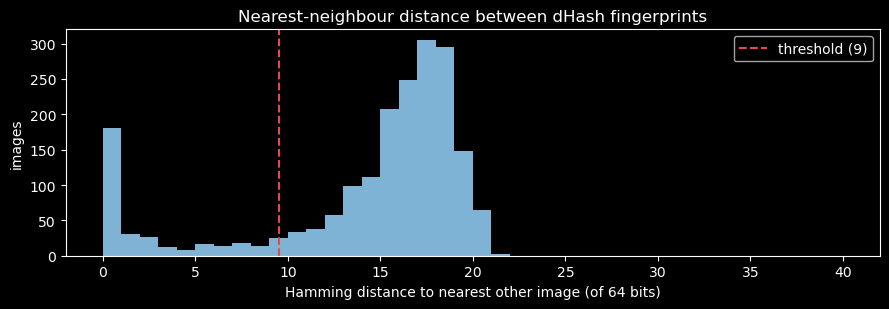

images with a neighbour at distance <= 9: 345


In [6]:
DUP_THRESHOLD = 9

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(nearest, bins=np.arange(0, 41), color='#7fb3d5')
ax.axvline(DUP_THRESHOLD + 0.5, color='#e5484d', ls='--', label=f'threshold ({DUP_THRESHOLD})')
ax.set_xlabel('Hamming distance to nearest other image (of 64 bits)')
ax.set_ylabel('images')
ax.set_title('Nearest-neighbour distance between dHash fingerprints')
ax.legend()
plt.tight_layout()
plt.show()

print(f'images with a neighbour at distance <= {DUP_THRESHOLD}: {(nearest <= DUP_THRESHOLD).sum()}')

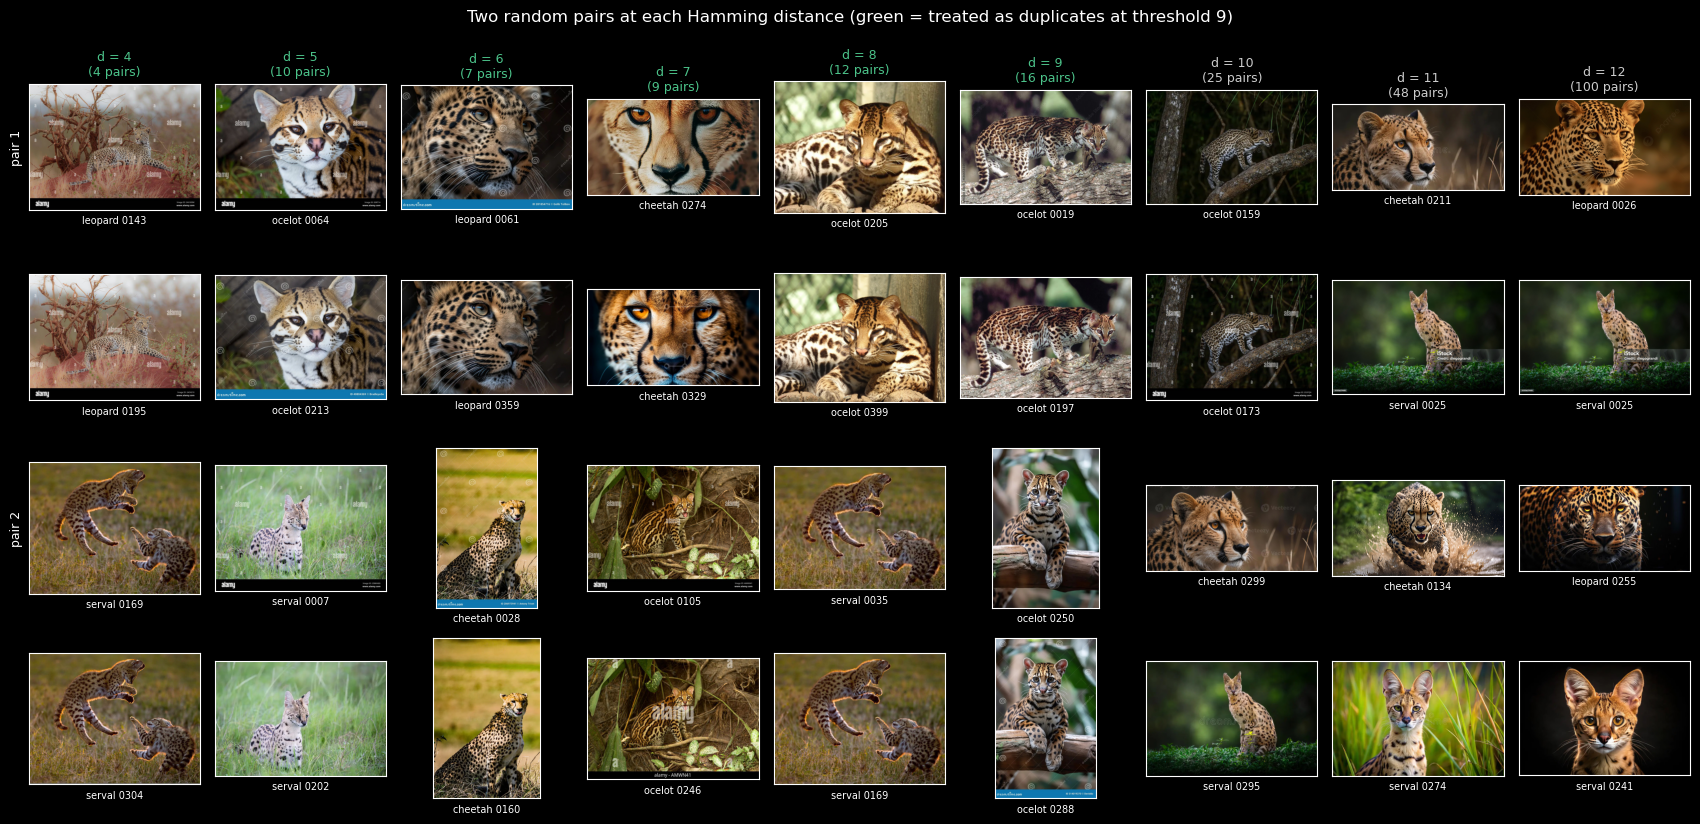

In [7]:
iu = np.triu_indices(len(kept_now), k=1)
pair_d = hamming[iu]
ladder = range(4, 13)
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(4, len(ladder), figsize=(1.9 * len(ladder), 8.2))
for col, d in enumerate(ladder):
    at_d = np.where(pair_d == d)[0]
    picks = rng.choice(at_d, size=min(2, len(at_d)), replace=False) if len(at_d) else []
    for p, k in enumerate(picks):
        for j, i in enumerate((iu[0][k], iu[1][k])):
            r = kept_now.iloc[i]
            axes[2 * p + j, col].imshow(Image.open(IMAGE_DIR / r['label'] / r['filename']))
            axes[2 * p + j, col].set_xlabel(f"{r['label']} {r['filename'][-8:-4]}", fontsize=7)
    for ax in axes[:, col]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[0, col].set_title(f'd = {d}\n({len(at_d)} pairs)', fontsize=9,
                           color='#4cc38a' if d <= DUP_THRESHOLD else '#cccccc')
axes[0, 0].set_ylabel('pair 1', fontsize=9); axes[2, 0].set_ylabel('pair 2', fontsize=9)
fig.suptitle(f'Two random pairs at each Hamming distance (green = treated as duplicates at threshold {DUP_THRESHOLD})',
             y=1.0)
plt.tight_layout()
plt.show()

**Reading the ladder.** At distances 4–6 every sampled pair is the same photo, most often re-hosted with a
different watermark or banner. The same is true at 7, 8 and 9. The leaping servals (0035 / 0169), the
ocelot on a log (0205 / 0399 and 0019 / 0197) and the ocelot with a Dreamstime banner (0250 / 0288) are
each one photo, pushed apart only by what a stock site added to it. The only doubtful pair below 10 is the two
cheetah face close-ups at 7, which may be the same photo re-coloured. The first clearly different photos
appear at 10 (a cheetah and a serval portrait), and from 11 on every sampled pair is two different photos.

**The threshold is therefore 9.** The two kinds of error do not cost the same. A missed duplicate can put
one photo in both train and test, which inflates test accuracy. A false match within one class costs one
image out of about 350. So when in doubt the threshold leans high. At 10, though, it would start removing genuinely
different photos, including cross-class pairs like the cheetah and serval at 10, where a match would
remove both images.

In [8]:
# Group images connected by any pair at or under the threshold (union-find).
parent = list(range(len(kept_now)))


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for a, b in zip(*np.where(np.triu(hamming <= DUP_THRESHOLD, k=1))):
    parent[find(a)] = find(b)

roots = np.array([find(i) for i in range(len(kept_now))])
groups = [np.where(roots == r)[0] for r in np.unique(roots) if (roots == r).sum() > 1]

dup_rows = []
for g, members in enumerate(groups):
    rows = kept_now.iloc[members]
    group_classes = '+'.join(sorted(rows['label'].unique()))
    if rows['label'].nunique() == 1:
        kind = 'within_class'
        best = rows.assign(px=rows['width'] * rows['height']).sort_values(
            ['px', 'filename'], ascending=[False, True]).index[0]
        removed = rows.drop(index=best)
    else:
        kind, removed = 'cross_class', rows
    dup_rows += [{'label': r.label, 'filename': r.filename, 'group': g, 'kind': kind,
                  'group_classes': group_classes} for r in removed.itertuples()]

duplicates = pd.DataFrame(dup_rows, columns=['label', 'filename', 'group', 'kind', 'group_classes'])
dup_keys = set(zip(duplicates['label'], duplicates['filename']))
manifest.loc[[k in dup_keys for k in zip(manifest['label'], manifest['filename'])], 'removal_reason'] = 'duplicate'

dup_summary = pd.DataFrame({kind: duplicates[duplicates['kind'] == kind]['label'].value_counts()
                            for kind in ['within_class', 'cross_class']}).reindex(CLASSES).fillna(0).astype(int)
dup_summary.loc['total'] = dup_summary.sum()

cross_pairs = duplicates[duplicates['kind'] == 'cross_class'].drop_duplicates('group')['group_classes'].value_counts()
print(f'{len(groups)} duplicate groups, {len(duplicates)} images removed as duplicates')
print('cross-class groups by class pair:', cross_pairs.to_dict() if len(cross_pairs) else 'none')
dup_summary

165 duplicate groups, 184 images removed as duplicates
cross-class groups by class pair: {'cheetah+leopard': 1, 'jaguar+leopard': 1, 'ocelot+serval': 1, 'cheetah+ocelot+serval': 1}


,within_class,cross_class
label,,
cheetah,21,3
jaguar,42,1
leopard,25,2
ocelot,48,2
serval,34,6
total,170,14


**Result.** At a threshold of 9, **184 images were removed as duplicates**: 170 extra copies within a class,
and 14 images from 4 groups whose copies spanned classes (cheetah + leopard, jaguar + leopard,
ocelot + serval, and one group joining cheetah, ocelot and serval). Duplicates cost far more than the hand
cleaning did (184 against 45). Ocelot lost the most (50), probably because fewer ocelot photos exist, so the same
stock images came back for several of its queries. One cross-class group is jaguar + leopard, the pair
Notebook 1 predicted would be confused most. The three-class group is probably a chain of near-matches (A close
to B, B close to C) rather than one photo. Removing it costs only a handful of images, and it guarantees that no
photo appears under two labels.

### 2.3 Final counts

One row per class, from what was scraped to what is kept. Every removed image is accounted for
by a reason, and the assertion checks the prompt's floor of 200 usable images per class.

In [9]:
accounting = (pd.crosstab(manifest['label'], manifest['removal_reason'])
                .reindex(index=CLASSES, columns=['', 'unreadable'] + HAND_REASONS + ['duplicate'], fill_value=0)
                .rename(columns={'': 'kept'}))
accounting.insert(0, 'scraped', manifest.groupby('label').size())
accounting = accounting[['scraped', 'unreadable'] + HAND_REASONS + ['duplicate', 'kept']]
assert (accounting['kept'] >= 200).all(), 'a class is below the 200-image minimum'
assert (accounting.drop(columns=['scraped']).sum(axis=1) == accounting['scraped']).all()

accounting.loc['total'] = accounting.sum()
accounting['pct_kept'] = (100 * accounting['kept'] / accounting['scraped']).round(1)
print('Every class clears the 200-image minimum.')
accounting

Every class clears the 200-image minimum.


removal_reason,scraped,unreadable,not_animal,drawing,wrong_species,unusable,duplicate,kept,pct_kept
label,,,,,,,,,
cheetah,400,0,0,0,2,0,24,374,93.5
jaguar,400,0,0,0,2,3,43,352,88.0
leopard,400,0,0,0,25,0,27,348,87.0
ocelot,400,0,0,1,0,0,50,349,87.2
serval,400,0,0,10,0,2,40,348,87.0
total,2000,0,0,11,29,5,184,1771,88.6


**1,771 of 2,000 images (88.6%) survive cleaning**, from 348 (leopard and serval) to 374 (cheetah) per class,
all well above the 200 minimum.

## 3. Image EDA

Everything in this section is measured on the **kept** images only. One pass over the files records
each image's size, colour mode and whether it is effectively grayscale, and adds it to its class's
running mean image. The mean image uses a plain stretch to 224×224, so it shows where image *content* tends
to sit in each class. Section 4.2 repeats it with the chosen resize to show what the model will actually see.

In [10]:
# width/height are re-measured from the files below, so the manifest's copies are dropped here.
kept = (manifest[manifest['removal_reason'] == ''].drop(columns=['width', 'height'])
        .sort_values(['label', 'filename']).reset_index(drop=True))

MEAN_SIZE = 224
mean_sums = {c: np.zeros((MEAN_SIZE, MEAN_SIZE, 3)) for c in CLASSES}
info = []

for r in kept.itertuples():
    with Image.open(IMAGE_DIR / r.label / r.filename) as img:
        mode, (w, h) = img.mode, img.size
        rgb = img.convert('RGB')
        small = np.asarray(rgb.resize((64, 64)), dtype=np.int16)
        mean_sums[r.label] += np.asarray(rgb.resize((MEAN_SIZE, MEAN_SIZE), Image.BILINEAR))
    # "Effectively grayscale": the three channels are nearly equal everywhere. This catches
    # black-and-white and night-time infrared camera-trap photos saved as RGB.
    channel_gap = (np.abs(small[..., 0] - small[..., 1]) + np.abs(small[..., 1] - small[..., 2])).mean()
    info.append({'width': w, 'height': h, 'mode': mode, 'grayscale': channel_gap < 4})

kept = pd.concat([kept, pd.DataFrame(info)], axis=1)
kept['aspect'] = kept['width'] / kept['height']
mean_images = {c: (mean_sums[c] / (kept['label'] == c).sum()).astype(np.uint8) for c in CLASSES}
print(f'{len(kept)} kept images measured')

1771 kept images measured


### 3.1 Sample grid

Eight randomly chosen kept images per class (seed 42), to show what the dataset actually looks like
after cleaning.

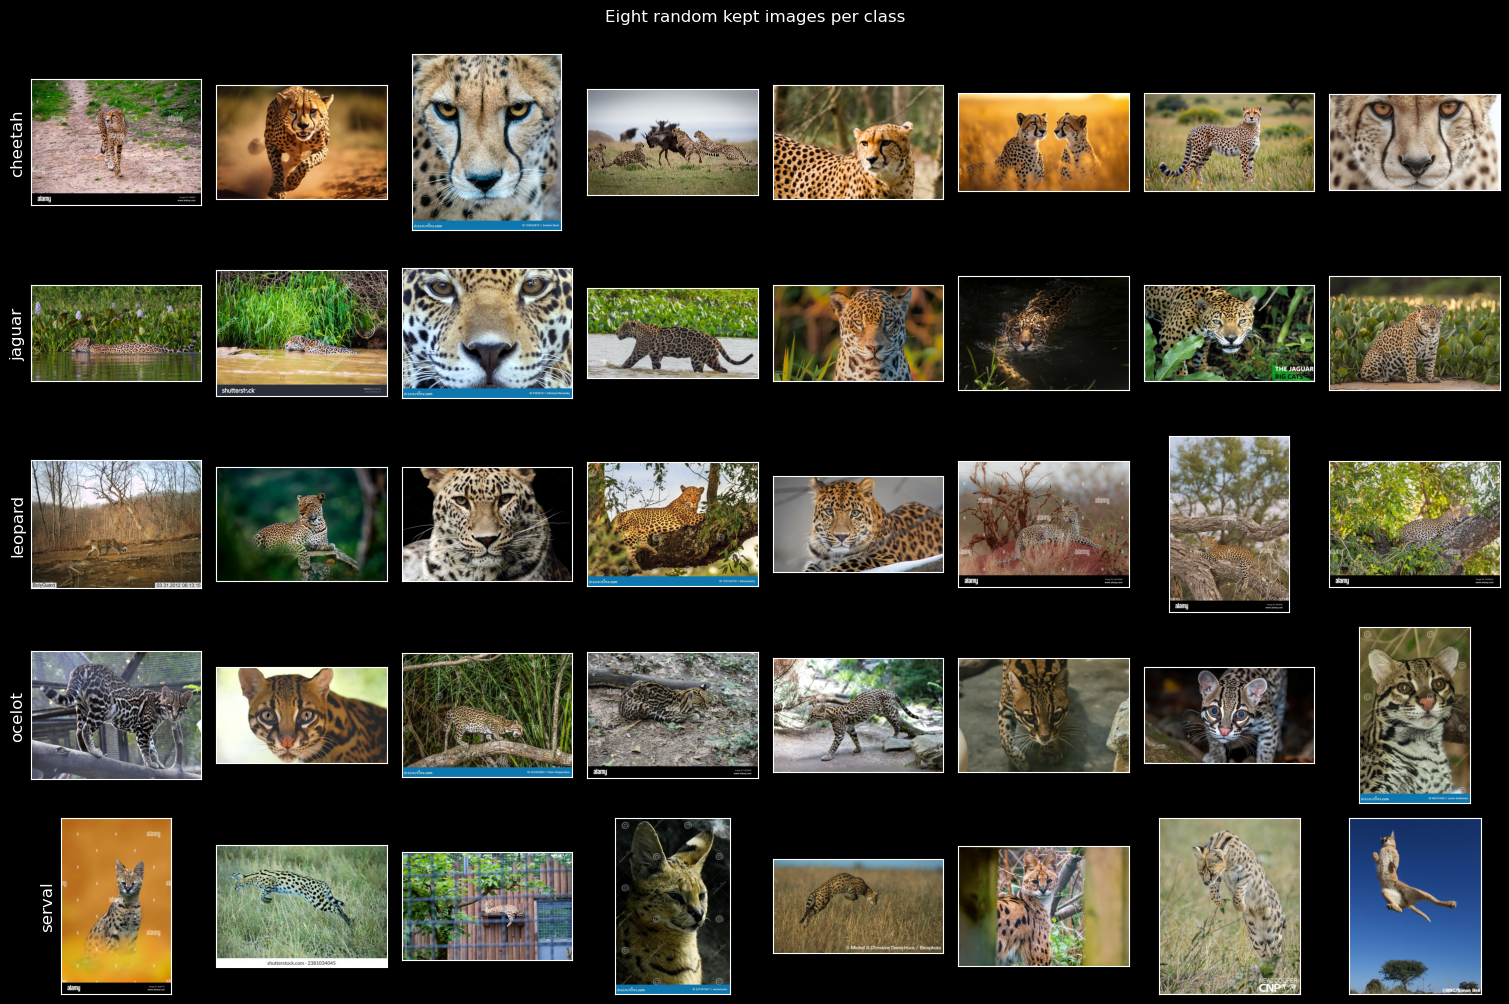

In [11]:
N_SAMPLE = 8
fig, axes = plt.subplots(len(CLASSES), N_SAMPLE, figsize=(1.9 * N_SAMPLE, 2.0 * len(CLASSES)))
for row, c in enumerate(CLASSES):
    sample = kept[kept['label'] == c].sample(N_SAMPLE, random_state=SEED)
    for col, r in enumerate(sample.itertuples()):
        ax = axes[row, col]
        ax.imshow(Image.open(IMAGE_DIR / r.label / r.filename))
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(c, fontsize=12)
plt.suptitle('Eight random kept images per class', y=1.0)
plt.tight_layout()
plt.show()

The grid shows what cleaning left: real photographs of the right animal, in a wide range of poses,
distances and settings, from full-body savanna and river scenes to tight face close-ups, zoo enclosures
and occasional groups (two cheetahs, a cheetah hunt). Three things recur across classes and are noted for Notebook 4:
**stock-photo watermarks and banners** (Alamy's footer, Dreamstime's blue strip, Shutterstock's caption bar)
appear in every row, **text overlays** appear occasionally (a "THE JAGUAR" title card), and at least one
colour **camera-trap photo** with a date stamp survived (the first leopard).

### 3.2 Image dimensions and aspect ratios

Notebook 1 required at least 224×224 and an aspect ratio between 0.5 and 2.0, so those are hard limits
here. Inside them, web images vary a lot. The question for section 4 is not only *how much* they vary,
but whether the shape of an image **differs by class**. If it does, any resize strategy that
leaves a visible trace of the original shape (padding bars, for example) would give the model a
shortcut.

,min,median,max
width,300.0,1050.0,8256.0
height,267.0,900.0,9504.0
aspect,0.5,1.5,2.0


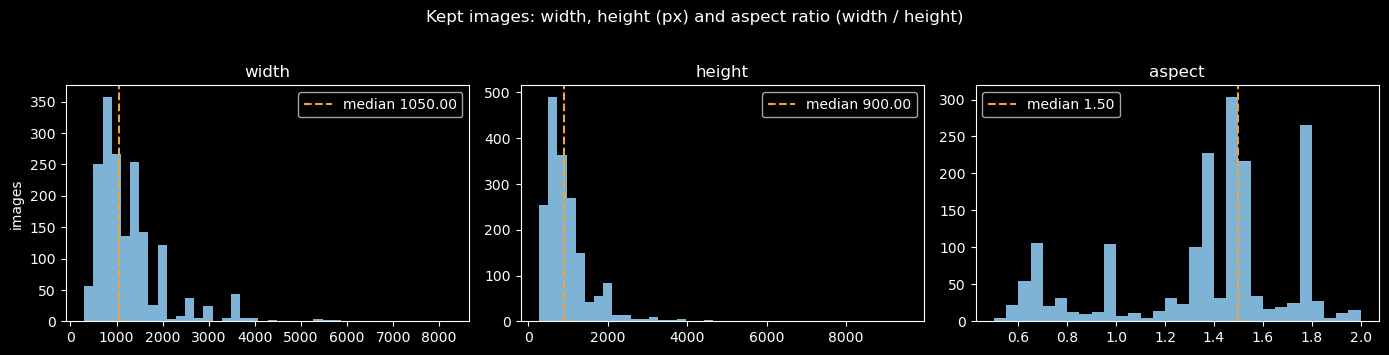

In [12]:
dims = kept[['width', 'height', 'aspect']].agg(['min', 'median', 'max']).T.round(2)
display(dims)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, col, bins in zip(axes, ['width', 'height', 'aspect'],
                         [40, 40, np.arange(0.5, 2.05, 0.05)]):
    ax.hist(kept[col], bins=bins, color='#7fb3d5')
    ax.axvline(kept[col].median(), color='#f2a33a', ls='--', label=f'median {kept[col].median():.2f}')
    ax.set_title(col); ax.legend()
axes[0].set_ylabel('images')
plt.suptitle('Kept images: width, height (px) and aspect ratio (width / height)', y=1.03)
plt.tight_layout()
plt.show()

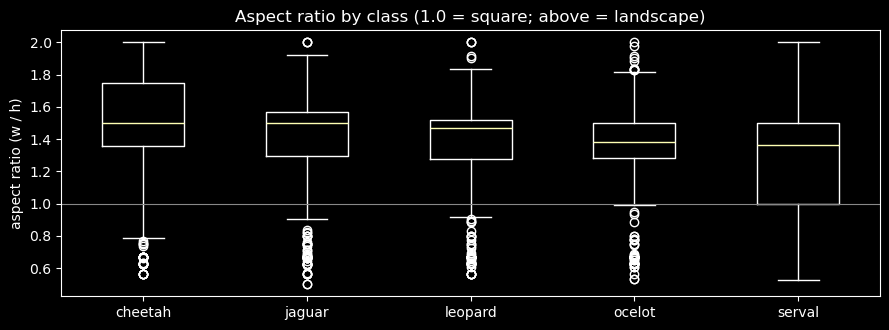

,median_aspect,portrait,square,landscape,median_width,median_height
label,,,,,,
cheetah,1.50,0.10,0.07,0.83,1024.0,700.0
jaguar,1.50,0.14,0.08,0.78,1242.5,939.0
leopard,1.47,0.15,0.07,0.78,1245.5,956.0
ocelot,1.38,0.13,0.08,0.79,992.0,736.0
serval,1.36,0.22,0.08,0.70,999.5,900.0


In [13]:
shape_by_class = kept.groupby('label').agg(
    median_aspect=('aspect', 'median'),
    portrait=('aspect', lambda a: (a < 0.9).mean()),
    square=('aspect', lambda a: a.between(0.9, 1.1).mean()),
    landscape=('aspect', lambda a: (a > 1.1).mean()),
    median_width=('width', 'median'),
    median_height=('height', 'median'),
).round(2)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.boxplot([kept.loc[kept['label'] == c, 'aspect'] for c in CLASSES])
ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES)
ax.axhline(1.0, color='#888', lw=0.8)
ax.set_ylabel('aspect ratio (w / h)')
ax.set_title('Aspect ratio by class (1.0 = square; above = landscape)')
plt.tight_layout()
plt.show()
shape_by_class

**Sizes are wildly inconsistent, as expected from the web.** Width runs from 300 to 8,256 px (median 1,050)
and height from 267 to 9,504 px (median 900), a range of about 27 to 1 in each direction. Aspect ratio fills the whole
0.5–2.0 band Notebook 1 allowed, with peaks at standard camera and stock formats: 3:2 (1.5), 4:3 (1.33), 16:9 (1.78),
square, and portrait 2:3 (0.67). Every image is larger than 224 px on both sides, so resizing only ever shrinks.

**By class, the shapes differ.** Cheetah photos are the widest (median aspect 1.50, 83% landscape, 10%
portrait) and serval photos are most often portrait (median 1.36, 22% portrait), with jaguar, leopard and
ocelot in between. Cheetahs are usually shot side-on and running, and servals sitting upright, so the
difference is real, not noise. It decides the resize strategy in 4.2.

### 3.3 Per-class mean image

Averaging every image in a class blurs away individual animals and leaves only what the class has in
common. A mean image that is uniform brownish blur is the healthy result: no position, border or colour is
consistent within the class. A recognisable shape, a bright centre, a coloured border or a strong
colour cast that differs between classes is something the model could use instead of the animal, and is
noted here for Notebook 4 to check.

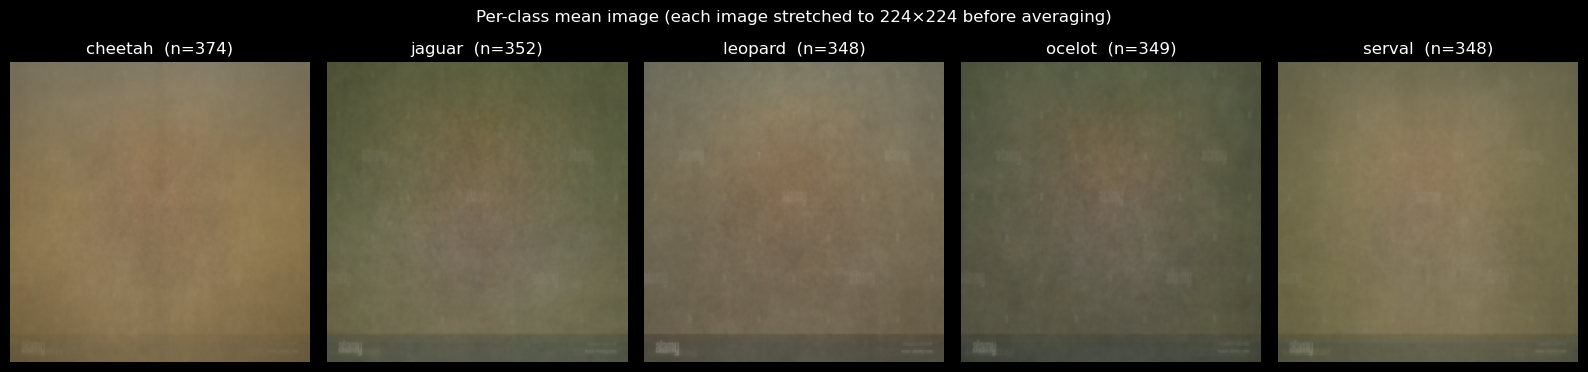

,R,G,B
cheetah,135.6,117.0,84.5
jaguar,104.6,101.5,74.9
leopard,117.8,107.5,86.0
ocelot,92.8,91.0,70.9
serval,120.3,111.7,82.0


In [14]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(3.2 * len(CLASSES), 3.6))
for ax, c in zip(axes, CLASSES):
    ax.imshow(mean_images[c])
    ax.set_title(f'{c}  (n={int((kept["label"] == c).sum())})')
    ax.axis('off')
plt.suptitle('Per-class mean image (each image stretched to 224×224 before averaging)', y=1.02)
plt.tight_layout()
plt.show()

mean_rgb = pd.DataFrame({c: mean_images[c].reshape(-1, 3).mean(axis=0) for c in CLASSES},
                        index=['R', 'G', 'B']).T.round(1)
mean_rgb

**No mean image shows an animal shape.** The cats appear at varied positions and sizes. Each has only a
slightly warmer, brighter patch near the centre, where photographers put the subject. What differs between classes is
**colour**. Cheetah and serval average warm yellow-brown (cheetah has the highest red, 136), while jaguar and ocelot
are darker and greener (red 105 and 93), and leopard sits in between. This is the habitat difference predicted in
Notebook 1, savanna against rainforest and river, and it is a possible shortcut: a model could partly separate cheetah
from jaguar by background colour. Two more structures appear in **every** class: a darker band along the bottom edge,
and faint repeated "alamy" text, from the stock-photo banners and watermarks in the sample grid. Because all five
classes share them, they cannot identify a class on their own, but their frequency may differ by class. Notebook 4 checks
the habitat colour and the watermarks.

### 3.4 Grayscale images by class

Wild ocelots and jaguars are often photographed by camera traps, which shoot at night in infrared and
save grayscale images, often with a timestamp printed on the frame. If grayscale photos cluster in
one or two classes, "no colour" becomes a cue that identifies those classes without looking at the coat. This was
flagged as a shortcut risk in Notebook 1, so it is measured here.

In [15]:
gray = kept.groupby('label')['grayscale'].agg(grayscale='sum', share='mean')
gray['share'] = (100 * gray['share']).round(1)
gray.rename(columns={'share': 'share_%'})

,grayscale,share_%
label,,
cheetah,1,0.3
jaguar,0,0.0
leopard,1,0.3
ocelot,3,0.9
serval,0,0.0


**Grayscale is not a concern.** Only 5 of 1,771 kept images (0.3%) are effectively grayscale: 3 ocelot, 1 cheetah
and 1 leopard. Night-time camera-trap photos did not survive in meaningful numbers, so "no colour" cannot act as a
class cue.

### 3.5 Class support

The number of kept images per class. Imbalance is **measured here, not fixed**. Balancing belongs in
Notebook 3, on the training set only, after the split: balancing before the split would put duplicated
or synthetic copies of training images into the test set.

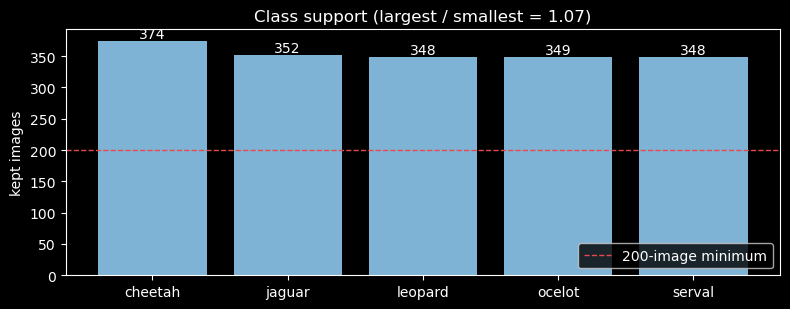

largest: cheetah (374), smallest: leopard (348), ratio 1.07


In [16]:
support = kept['label'].value_counts().reindex(CLASSES)
ratio = support.max() / support.min()

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(CLASSES, support.values, color='#7fb3d5')
ax.bar_label(bars)
ax.axhline(200, color='#e5484d', ls='--', lw=1, label='200-image minimum')
ax.set_ylabel('kept images')
ax.set_title(f'Class support (largest / smallest = {ratio:.2f})')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'largest: {support.idxmax()} ({support.max()}), smallest: {support.idxmin()} ({support.min()}), '
      f'ratio {ratio:.2f}')

**The imbalance is mild:** 374 cheetah against 348 leopard and 348 serval, a ratio of 1.07. Notebook 3 still applies
a balancing step to the training set, but at this ratio it changes little.

## 4. Preprocessing decisions

Two decisions turn the kept images into the identical-shape arrays Notebook 3 needs. Each must be
applied **identically** in the Streamlit app, so both are written to `preprocess.json` next to the arrays
in section 5.

### 4.1 Colour mode: 3-channel RGB

Every Keras application in Notebook 3 expects three-channel RGB input, so every image is converted
with `Image.convert('RGB')`. Grayscale images become three identical channels, and any image with an
alpha (transparency) channel loses it.

In [17]:
kept['mode'].value_counts().rename('images').to_frame()

,images
mode,
RGB,1771


All kept files are already RGB, because Notebook 1's scraper converts each download with `convert('RGB')`
before saving it as JPEG. The conversion is still applied here, because the Streamlit app will receive
user uploads in any mode (grayscale, RGBA PNG, palette GIF), and the pipeline must be identical in both
places.

One consequence of the scraper's conversion is worth recording: a transparent PNG had its transparent background
filled in with a solid colour when it was saved. Cut-out "product shot" images of an animal on a flat background
would therefore look unlike any natural photo. Such images were the kind removed as `unusable` in 2.1.

### 4.2 Resize strategy: center-crop to 224×224

The images range widely in size and shape (3.2), and every model needs one fixed input size. We use
**224×224**, which is the standard input for the Keras applications we will use, and the size Notebook 1's minimum
resolution was chosen to match. The three options from `U2-1_Images-1_SkimageCV2` §2–3, compared below on
the most portrait, the most landscape and a typical image, each cost something different for this subject:

| Strategy | What it does | What it costs for spotted cats |
|---|---|---|
| **Stretch** | Resize straight to 224×224 | Distorts body proportions. A 2:1 photo is squashed to half its width, so a long, slender cheetah or serval looks stocky like a jaguar. **Body build is one of the real cues between these classes**, so this damages the signal itself |
| **Center-crop** | Cut the largest centred square, then resize | Keeps proportions, but throws away up to half of a 2:1 image. In wide wildlife shots the cat is often off-centre or long, so the head, tail or tear marks can be cut off |
| **Pad** | Shrink so the longer side is 224, then pad the short side with black bars | Keeps proportions **and** the whole animal. Costs some resolution on the long side, and adds bars whose size depends on the image's shape |

**We choose center-crop.** Stretch is ruled out because it distorts body build, a real cue between these
classes. Pad and crop both keep proportions, and the deciding evidence is section 3.2: **image shape differs
by class.** About 10% of cheetah photos are portrait, against about 20% of serval photos, and cheetah
photos are the widest (median aspect about 1.5, against about 1.4 for ocelot and serval). Under padding,
an image's shape decides where its black bars fall, so the bar layout would carry class information that has
nothing to do with the cat. That would be a shortcut built into the preprocessing itself. A centre crop leaves no
trace of the original shape.

Crop also spends all 224×224 pixels on the photo. At the median aspect ratio of 1.5, padding would spend a third of
the input on black bars and shrink the cat to fit, while cropping keeps the cat larger, with more pixels on
the spots and rosettes that separate the classes.

**What it costs:** the outer edges of wide images. A 1.5:1 photo loses a third of its width and a 2:1 photo loses half,
split between left and right. Photographers usually centre the animal, and in the comparison below the cat
stays in frame in all three examples, but an animal near the edge of a wide shot (a running cheetah's head or
tail, say) can be partly cut off. We accept that cost. The Streamlit app must apply exactly the same
centre crop.

Downscaling uses Lanczos resampling, which keeps fine texture (spots and rosettes) sharper than bilinear.

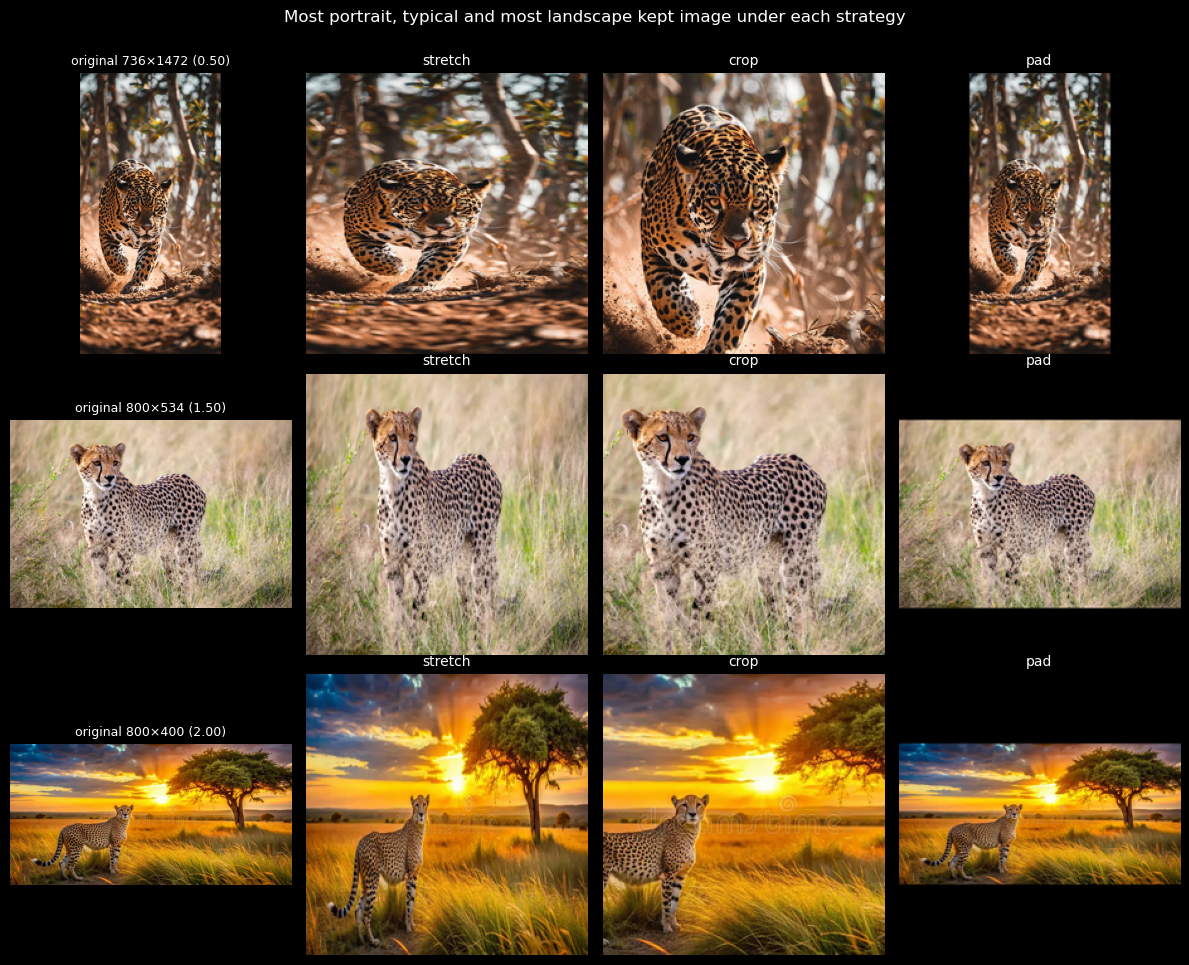

In [18]:
TARGET_SIZE = 224
RESIZE_MODE = 'crop'         # 'crop' chosen; 'pad' and 'stretch' are shown for comparison only
PAD_FILL = (0, 0, 0)         # used only by 'pad' in the comparison figure


def resize_image(img, size=TARGET_SIZE, mode=RESIZE_MODE, fill=PAD_FILL):
    # RGB, then make square by the chosen strategy, then resize to size×size with Lanczos.
    img = img.convert('RGB')
    w, h = img.size
    if mode == 'stretch':
        square = img
    elif mode == 'crop':
        s = min(w, h)
        left, top = (w - s) // 2, (h - s) // 2
        square = img.crop((left, top, left + s, top + s))
    elif mode == 'pad':
        s = max(w, h)
        square = Image.new('RGB', (s, s), fill)
        square.paste(img, ((s - w) // 2, (s - h) // 2))
    else:
        raise ValueError(f'unknown resize mode {mode!r}')
    return square.resize((size, size), Image.LANCZOS)


examples = [kept['aspect'].idxmin(), (kept['aspect'] - kept['aspect'].median()).abs().idxmin(),
            kept['aspect'].idxmax()]
fig, axes = plt.subplots(len(examples), 4, figsize=(12, 3.2 * len(examples)))
for row, i in enumerate(examples):
    r = kept.loc[i]
    img = Image.open(IMAGE_DIR / r['label'] / r['filename'])
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"original {r['width']}×{r['height']} ({r['aspect']:.2f})", fontsize=9)
    for col, mode in enumerate(['stretch', 'crop', 'pad'], start=1):
        axes[row, col].imshow(resize_image(img, mode=mode))
        axes[row, col].set_title(mode, fontsize=10)
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle('Most portrait, typical and most landscape kept image under each strategy', y=1.0)
plt.tight_layout()
plt.show()

The comparison shows each cost directly. **Stretch** visibly distorts the animals: the portrait jaguar is
squashed wide, and the 2:1 cheetah is pulled tall and slender. **Pad** keeps everything but shrinks the cat. In the 2:1
image the cheetah fills only a small strip between thick black bars. **Crop** keeps proportions and fills the
frame with the subject in all three: it trims background above and below the portrait jaguar, grass from the sides of
the typical cheetah, and sky and tree from the 2:1 image, while each cat stays whole.

Every kept image is now resized with the chosen strategy into one `uint8` array, with values 0–255.
`preprocess_input` is **not** applied: each Keras application in Notebook 3 needs its own
scaling, so the arrays stay raw. The per-class mean image after cropping is shown again, to confirm the
model's input carries no border or shape trace.

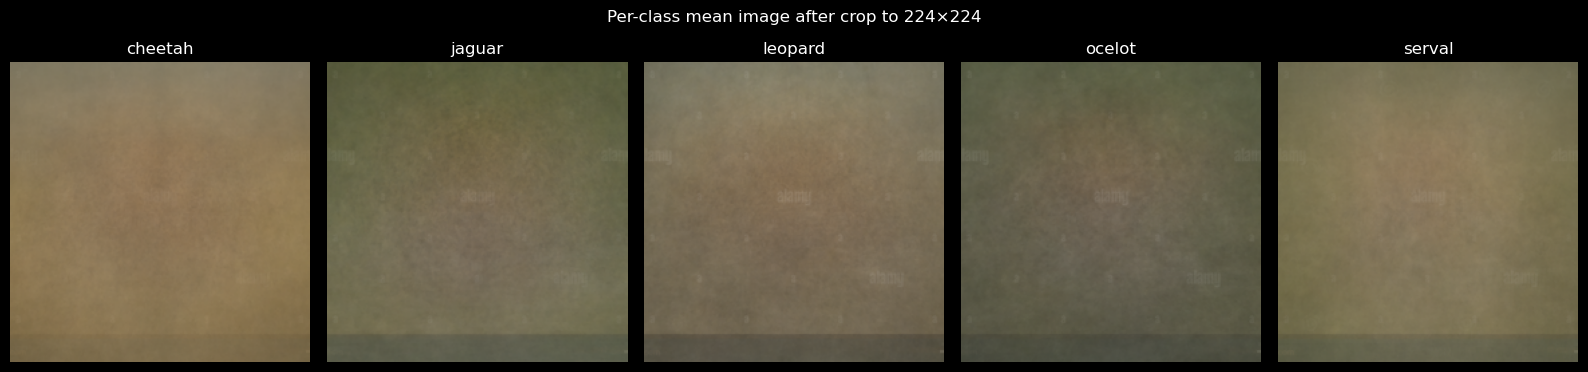

X_all: (1771, 224, 224, 3) uint8, 267 MB, values 0–255


In [19]:
X_all = np.empty((len(kept), TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
for i, r in enumerate(kept.itertuples()):
    with Image.open(IMAGE_DIR / r.label / r.filename) as img:
        X_all[i] = np.asarray(resize_image(img))

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3.2 * len(CLASSES), 3.6))
for ax, c in zip(axes, CLASSES):
    ax.imshow(X_all[(kept['label'] == c).values].mean(axis=0).astype(np.uint8))
    ax.set_title(c); ax.axis('off')
plt.suptitle(f'Per-class mean image after {RESIZE_MODE} to {TARGET_SIZE}×{TARGET_SIZE}', y=1.02)
plt.tight_layout()
plt.show()

print(f'X_all: {X_all.shape} {X_all.dtype}, {X_all.nbytes / 1e6:.0f} MB, values {X_all.min()}–{X_all.max()}')

**After cropping, the per-class mean images have no bars or borders**, so the model's input carries no trace of
each image's original shape. The habitat colours and the faint watermark band along the bottom remain, because
they are part of the photos themselves.

## 5. Split and export

### 5.1 Stratified 80/20 split

The kept images are split 80% train, 20% test, **stratified by class** so each class has the same
share in both, with `random_state=42`. Nothing is balanced or augmented before the split. Both happen
in Notebook 3, on the training set only. Doing either here would put copies, or altered copies, of
training images into the test set, and the test accuracy would be fiction.

The label→index mapping is alphabetical, so anyone can rebuild it from the class names. It is saved
to `label_map.json`, and Notebook 3, Notebook 4 and the app all load that file rather than recomputing
it. If any of them got the order wrong, the class names would be silently permuted.

In [20]:
label_map = {c: i for i, c in enumerate(CLASSES)}
y_all = kept['label'].map(label_map).to_numpy(dtype=np.int64)

train_idx, test_idx = train_test_split(np.arange(len(kept)), test_size=0.2,
                                       stratify=y_all, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)

kept['split'] = ''
kept.loc[train_idx, 'split'] = 'train'
kept.loc[test_idx, 'split'] = 'test'

split_counts = pd.crosstab(kept['label'], kept['split'])[['train', 'test']]
split_counts.loc['total'] = split_counts.sum()
split_counts['test_%'] = (100 * split_counts['test'] / split_counts.sum(axis=1)).round(1)
label_map, split_counts

({'cheetah': 0, 'jaguar': 1, 'leopard': 2, 'ocelot': 3, 'serval': 4},
 split    train  test  test_%
 label                       
 cheetah    299    75    20.1
 jaguar     282    70    19.9
 leopard    278    70    20.1
 ocelot     279    70    20.1
 serval     278    70    20.1
 total     1416   355    20.0)

The split is stratified as intended: every class has 19.9–20.1% of its images in test, for 1,416 training and 355
test images in total.

### 5.2 Export

Everything is saved to `PREP_DIR`, in the local data folder outside the repo:

| File | Contents |
|---|---|
| `X_train.npy`, `X_test.npy` | `uint8` arrays, shape `(n, 224, 224, 3)`, raw 0–255 RGB, resized as in 4.2 |
| `y_train.npy`, `y_test.npy` | `int64` class indices, using `label_map.json` |
| `files_train.csv`, `files_test.csv` | One row per array row (`label`, `filename`, `y`), in the same order, so any image in Notebook 4 can be traced back to its file and its manifest row |
| `label_map.json` | `{class name: index}` |
| `preprocess.json` | The resize settings from 4.2, for Notebook 3, Notebook 4 and the app to reproduce exactly |

`.npy` arrays load in one line with `np.load`, with no decoding and no chance that a loader resizes or
reorders images differently from here. The full arrays are a few hundred MB, small enough to hold in memory in
Notebook 3.

In [21]:
PREP_DIR.mkdir(parents=True, exist_ok=True)

for name, idx in [('train', train_idx), ('test', test_idx)]:
    np.save(PREP_DIR / f'X_{name}.npy', X_all[idx])
    np.save(PREP_DIR / f'y_{name}.npy', y_all[idx])
    kept.loc[idx, ['label', 'filename']].assign(y=y_all[idx]).to_csv(PREP_DIR / f'files_{name}.csv', index=False)

(PREP_DIR / 'label_map.json').write_text(json.dumps(label_map, indent=2))
(PREP_DIR / 'preprocess.json').write_text(json.dumps(
    {'target_size': TARGET_SIZE, 'resize_mode': RESIZE_MODE, 'crop': 'centre square, side = min(width, height)',
     'resample': 'LANCZOS', 'color_mode': 'RGB', 'dtype': 'uint8', 'value_range': [0, 255]}, indent=2))

print(f'Saved to {PREP_DIR}:')
for p in sorted(PREP_DIR.iterdir()):
    print(f'  {p.name:<18} {p.stat().st_size / 1e6:8.1f} MB')

Saved to C:\Users\grego\MSDS565_data\P2_prepared:
  files_test.csv          0.0 MB
  files_train.csv         0.0 MB
  label_map.json          0.0 MB
  preprocess.json         0.0 MB
  X_test.npy             53.4 MB
  X_train.npy           213.1 MB
  y_test.npy              0.0 MB
  y_train.npy             0.0 MB


A read-back check: load what was written, exactly as Notebook 3 will, and confirm shapes, types, value
range, label order and that no file appears in both splits.

In [22]:
X_train, X_test = np.load(PREP_DIR / 'X_train.npy'), np.load(PREP_DIR / 'X_test.npy')
y_train, y_test = np.load(PREP_DIR / 'y_train.npy'), np.load(PREP_DIR / 'y_test.npy')
files_train, files_test = pd.read_csv(PREP_DIR / 'files_train.csv'), pd.read_csv(PREP_DIR / 'files_test.csv')
loaded_map = json.loads((PREP_DIR / 'label_map.json').read_text())

assert X_train.shape[1:] == X_test.shape[1:] == (TARGET_SIZE, TARGET_SIZE, 3)
assert X_train.dtype == X_test.dtype == np.uint8
assert len(X_train) == len(y_train) == len(files_train) and len(X_test) == len(y_test) == len(files_test)
assert loaded_map == label_map
assert (files_train['label'].map(loaded_map) == y_train).all() and (files_test['label'].map(loaded_map) == y_test).all()
assert not set(zip(files_train['label'], files_train['filename'])) & set(zip(files_test['label'], files_test['filename']))

print(f'train: X {X_train.shape}, y {y_train.shape} | test: X {X_test.shape}, y {y_test.shape}')
print('All read-back checks passed.')

train: X (1416, 224, 224, 3), y (1416,) | test: X (355, 224, 224, 3), y (355,)
All read-back checks passed.


### 5.3 Updating the manifest

Three columns are added to Notebook 1's manifest; every existing column and row is left as it was:

- `kept`: True if the image survived cleaning and is in one of the arrays
- `removal_reason`: empty for kept images, otherwise `unreadable`, one of the four hand-cleaning reasons, or `duplicate`
- `split`: `train` or `test` for kept images, empty otherwise

In [23]:
split_lookup = dict(zip(zip(kept['label'], kept['filename']), kept['split']))
manifest['kept'] = manifest['removal_reason'].eq('')
manifest['split'] = [split_lookup.get(k, '') for k in zip(manifest['label'], manifest['filename'])]

assert manifest.loc[manifest['kept'], 'split'].isin(['train', 'test']).all()
assert manifest.loc[~manifest['kept'], 'split'].eq('').all()

manifest.to_csv(MANIFEST_PATH, index=False)
print(f'{MANIFEST_PATH} updated: {len(manifest)} rows, columns {list(manifest.columns)}')
pd.crosstab(manifest['removal_reason'].replace('', '(kept)'), manifest['split'].replace('', '—'))

C:\Users\grego\P2_Images\data\P2_manifest.csv updated: 2000 rows, columns ['filename', 'label', 'query', 'image_url', 'source_url', 'title', 'width', 'height', 'readable', 'removal_reason', 'kept', 'split']


split,test,train,—
removal_reason,,,
(kept),355,1416,0
drawing,0,0,11
duplicate,0,0,184
unusable,0,0,5
wrong_species,0,0,29


## Review

1. **Hand cleaning** removed 45 of 2,000 images (2.2%), sorted into reason folders by moving the files, so every removal
   is counted from disk. The animal words in Notebook 1's queries kept cars, logos and print fabric out entirely
2. **Duplicate removal** used 64-bit difference hashes across all five classes. The threshold of 9 was chosen from a
   figure of sample pairs at each distance. It removed 184 images: 170 extra within-class copies and 14 cross-class
   images, every copy of which was dropped because the labels conflict. All of this happened before the split
3. **1,771 images survive**, 348–374 per class, all well above the 200 minimum, with a mild 1.07 imbalance that is
   measured here and left for Notebook 3
4. **EDA:** image sizes vary about 27 to 1, image shape differs by class (cheetah widest, serval most often portrait),
   mean images show a habitat colour split (warm savanna for cheetah and serval, green for jaguar and ocelot), and
   grayscale photos are negligible
5. **Preprocessing:** RGB, then a centre square crop resized to 224×224 with Lanczos. Stretching was rejected because it
   distorts body build. Padding was rejected because its bars would encode image shape, which differs by class
6. **Split and export:** stratified 80/20 with `random_state=42` (1,416 / 355), saved as raw `uint8` arrays with
   `label_map.json` and `preprocess.json`, and the manifest gained `kept`, `removal_reason` and `split`

**Carried forward to Notebook 4:** the habitat colour difference between classes (3.3) and the stock-photo watermarks,
banners and text overlays seen in every class (3.1, 3.3) are the two things to check the Grad-CAM maps against.

**Next:** `P2_Images-3_TransferLearning_<TeamName>.ipynb` loads these arrays, balances and augments the training
set, and compares at least three Keras applications.